# LAB 2: Implementation of Simple Linear Regression

## 1. Objectives
- Understand the mathematics of **Simple Linear Regression**: $y = \beta_0 + \beta_1 x + \varepsilon$.
- Split a dataset into training and testing sets.
- Fit the model with `scikit-learn`.
- Evaluate it with **MSE, RMSE and R²**.
- Visualise the regression line against the data.
- (Extra) Compare the closed-form OLS solution with **Gradient Descent**.

## 2. Software & Libraries
`numpy`, `pandas`, `matplotlib`, `seaborn`, `sklearn.model_selection`, `sklearn.linear_model`, `sklearn.metrics`

## 3. Implementation
### Step 1: Generate the data
Study hours (`X`) vs exam score (`y`) with a true relationship `score = 35 + 5.5*hours` plus Gaussian noise. The data is saved to a CSV file.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
np.random.seed(42)

n = 100
hours = np.round(np.random.uniform(1, 10, n), 2)
score = 35 + 5.5 * hours + np.random.normal(0, 4, n)
df = pd.DataFrame({"Hours_Studied": hours, "Exam_Score": score.round(2)})
df.to_csv("simple_linear_regression_data.csv", index=False)

display(df.head())
display(df.describe().round(2))

,Hours_Studied,Exam_Score
0,4.37,59.38
1,9.56,86.38
2,7.59,77.11
3,6.39,62.19
4,2.40,47.32


,Hours_Studied,Exam_Score
count,100.00,100.00
mean,5.23,63.77
std,2.68,14.63
min,1.05,39.08
25%,2.74,51.48
50%,5.18,61.92
75%,7.58,76.74
max,9.88,92.47


### Step 2: Splitting data into training and testing sets (80 / 20)

In [2]:
X = df[["Hours_Studied"]]
y = df["Exam_Score"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (80, 1)  Test: (20, 1)


### Step 3: Training the model (Ordinary Least Squares)

In [3]:
model = LinearRegression()
model.fit(X_train, y_train)
print(f"Intercept (beta_0): {model.intercept_:.4f}   (true value 35)")
print(f"Slope     (beta_1): {model.coef_[0]:.4f}   (true value 5.5)")

Intercept (beta_0): 35.7507   (true value 35)
Slope     (beta_1): 5.3215   (true value 5.5)


### Step 4: Predictions & model evaluation

In [4]:
y_pred_train = model.predict(X_train)
y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R^2  : {r2:.4f}   (train R^2 = {r2_score(y_train, y_pred_train):.4f})")

MSE  : 10.4630
RMSE : 3.2347
R^2  : 0.9536   (train R^2 = 0.9348)


### Step 5: Visualising the results

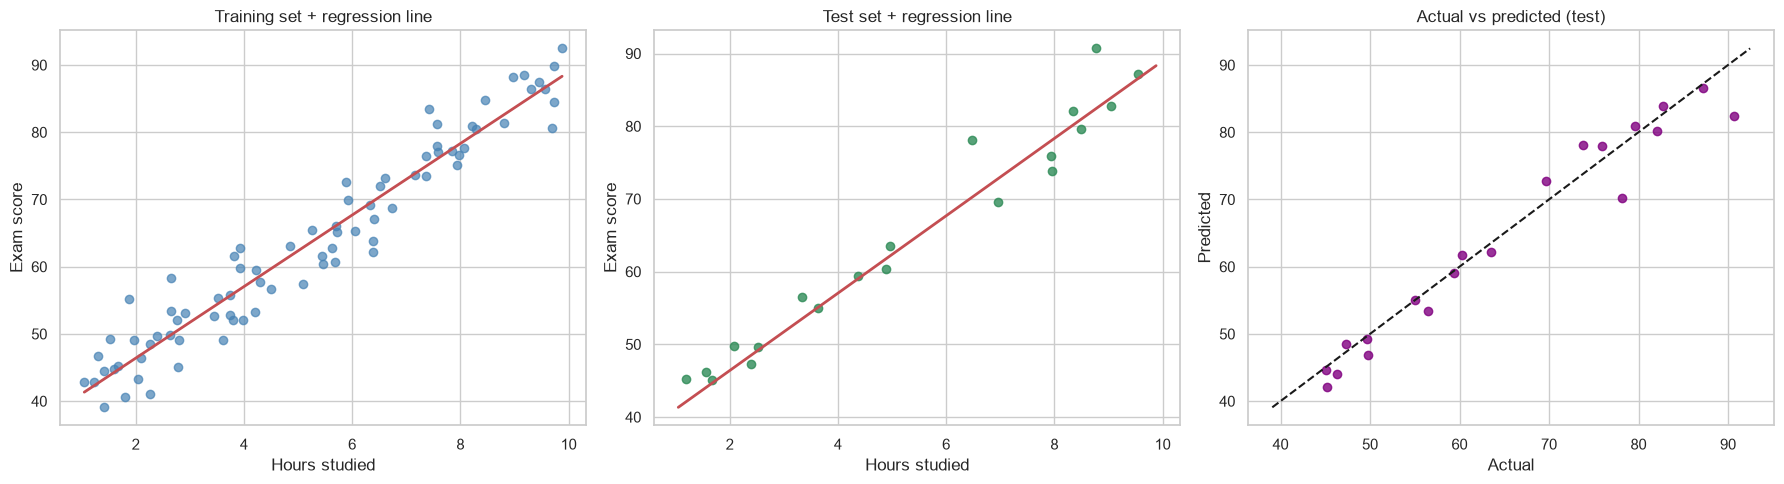

In [5]:
xs = np.linspace(X["Hours_Studied"].min(), X["Hours_Studied"].max(), 100).reshape(-1, 1)
line = model.predict(pd.DataFrame(xs, columns=["Hours_Studied"]))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(X_train, y_train, c="steelblue", alpha=.7); axes[0].plot(xs, line, "r-", lw=2)
axes[0].set_title("Training set + regression line")
axes[1].scatter(X_test, y_test, c="seagreen", alpha=.8); axes[1].plot(xs, line, "r-", lw=2)
axes[1].set_title("Test set + regression line")
axes[2].scatter(y_test, y_pred, c="purple", alpha=.8)
axes[2].plot([y.min(), y.max()], [y.min(), y.max()], "k--"); axes[2].set_title("Actual vs predicted (test)")
for a, (xl, yl) in zip(axes, [("Hours studied", "Exam score")] * 2 + [("Actual", "Predicted")]):
    a.set_xlabel(xl); a.set_ylabel(yl)
plt.tight_layout(); plt.show()

### Extra: OLS (closed form) vs Gradient Descent
Gradient descent minimises the same MSE iteratively: $\beta \leftarrow \beta - \eta \nabla J$. The feature is standardised first so a fixed learning rate converges quickly, then the parameters are converted back to the original scale.

,Metric,OLS,Gradient Descent
0,Intercept,35.7507,35.7507
1,Slope,5.3215,5.3215
2,MSE,10.4630,10.4630
3,RMSE,3.2347,3.2347
4,R2,0.9536,0.9536


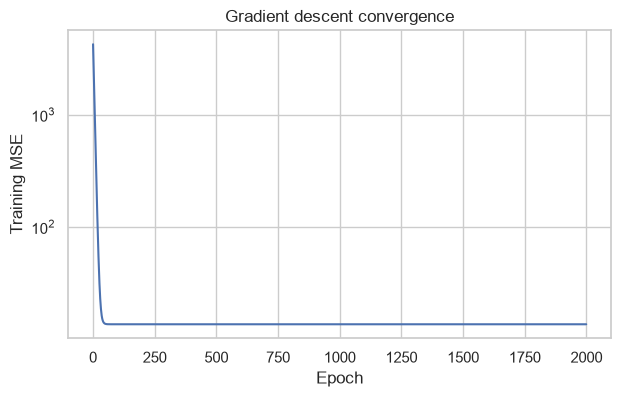

In [6]:
mu, sd = X_train["Hours_Studied"].mean(), X_train["Hours_Studied"].std()
xtr = ((X_train["Hours_Studied"] - mu) / sd).values
ytr = y_train.values
m, b, lr, epochs, N = 0.0, 0.0, 0.05, 2000, len(xtr)
losses = []
for _ in range(epochs):
    err = (m * xtr + b) - ytr
    m -= lr * (2 / N) * np.sum(err * xtr)
    b -= lr * (2 / N) * np.sum(err)
    losses.append(np.mean(err ** 2))

slope_gd = m / sd
intercept_gd = b - m * mu / sd
y_pred_gd = slope_gd * X_test["Hours_Studied"].values + intercept_gd
gd_mse = mean_squared_error(y_test, y_pred_gd)

cmp = pd.DataFrame({
    "Metric": ["Intercept", "Slope", "MSE", "RMSE", "R2"],
    "OLS": [model.intercept_, model.coef_[0], mse, rmse, r2],
    "Gradient Descent": [intercept_gd, slope_gd, gd_mse, np.sqrt(gd_mse), r2_score(y_test, y_pred_gd)],
}).round(4)
display(cmp)

plt.figure(figsize=(7, 4)); plt.plot(losses); plt.yscale("log")
plt.title("Gradient descent convergence"); plt.xlabel("Epoch"); plt.ylabel("Training MSE"); plt.show()

## 4. Observations & Summary Table
| Phase | Action Taken | Purpose / Result |
|---|---|---|
| Data separation | Defined `X` feature matrix and `y` target vector | Structured input format required by scikit-learn. |
| Data splitting | `train_test_split(test_size=0.2)` | Reserved unseen test data for unbiased evaluation. |
| Model training | `model.fit(X_train, y_train)` | Solved OLS to obtain $\beta_0$ and $\beta_1$. |
| Evaluation | MSE, RMSE, R² | Measured error magnitude and variance explained. |
| Visualisation | Scatter plots & regression line | Confirmed the linear fit visually. |

## 5. Conclusion
- The model recovered intercept and slope close to the true values (35 and 5.5) used to generate the data.
- The high R² on the test set shows that a single feature explains most of the variance of the target.
- Train and test fits are similar, so the model generalises without overfitting.
- Gradient descent converges to essentially the same line as the OLS closed-form solution.